# Local Volume: Stellar Population & Kinematics

Deep dive into the 38,847 Gaia DR3 sources within 150 ly.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
BASE = '/home/dawe/Projects/astro-science/research/projects/local-volume'
df = pd.read_csv(f'{BASE}/data/processed/local_volume_gaia_full.csv')
print(f'Total: {len(df):,} sources')
print(f'With Teff: {df["teff_gspphot"].notna().sum():,}')
print(f'With RV: {df["radial_velocity"].notna().sum():,}')


Total: 38,847 sources
With Teff: 12,265
With RV: 21,757


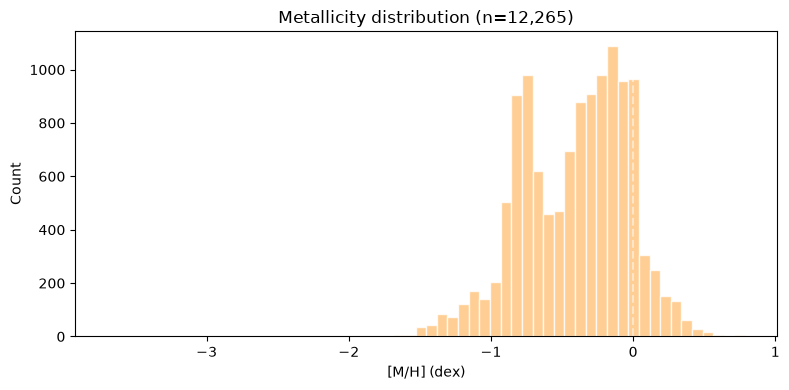

Median [M/H]: -0.358 dex
Std: 0.379 dex


In [2]:
# Metallicity distribution
mh = df['mh_gspphot'].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(mh, bins=60, color='#ffc27a', edgecolor='white', alpha=0.8)
ax.set_xlabel('[M/H] (dex)')
ax.set_ylabel('Count')
ax.set_title(f'Metallicity distribution (n={len(mh):,})')
ax.axvline(0, color='white', linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()
print(f'Median [M/H]: {mh.median():.3f} dex')
print(f'Std: {mh.std():.3f} dex')


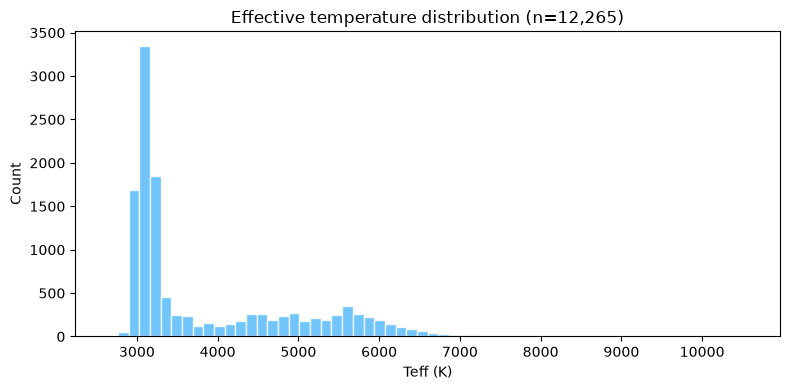

Median Teff: 3219 K


In [3]:
# Teff distribution
teff = df['teff_gspphot'].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(teff, bins=60, color='#4fb7fb', edgecolor='white', alpha=0.8)
ax.set_xlabel('Teff (K)')
ax.set_ylabel('Count')
ax.set_title(f'Effective temperature distribution (n={len(teff):,})')
plt.tight_layout(); plt.show()
print(f'Median Teff: {teff.median():.0f} K')


Sources with full 6D phase space: 21,757


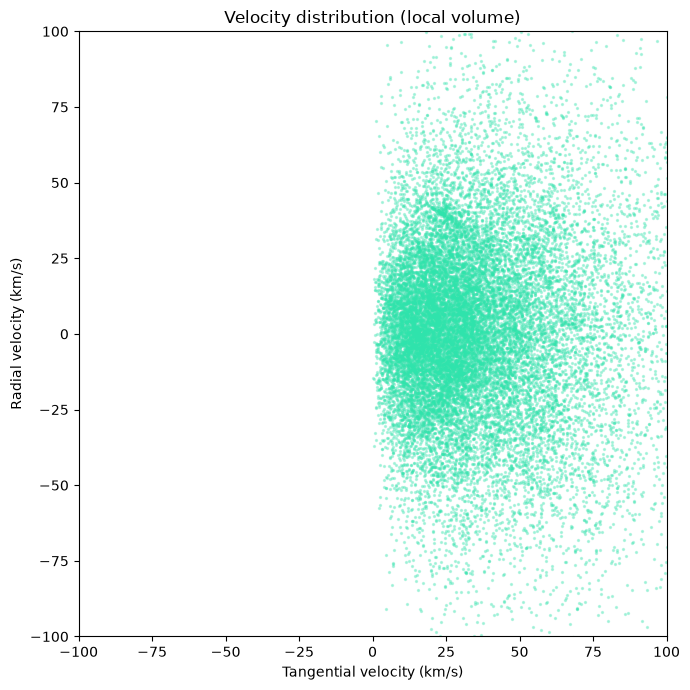

In [4]:
# Toomre diagram (UVW kinematics approximation using pm + RV)
has_kin = df['radial_velocity'].notna() & df['pmra'].notna() & df['pmdec'].notna() & df['parallax'].notna()
k = df[has_kin].copy()
print(f'Sources with full 6D phase space: {len(k):,}')
# Approximate tangential velocity
k['vt'] = 4.74 * np.sqrt(k['pmra']**2 + k['pmdec']**2) / k['parallax']
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(k['vt'], k['radial_velocity'], s=2, alpha=0.3, c='#2fe3ac')
ax.set_xlabel('Tangential velocity (km/s)')
ax.set_ylabel('Radial velocity (km/s)')
ax.set_title('Velocity distribution (local volume)')
ax.set_xlim(-100, 100); ax.set_ylim(-100, 100)
plt.tight_layout(); plt.show()


Exoplanet host stars: 560
Planets per host (median): 1.0


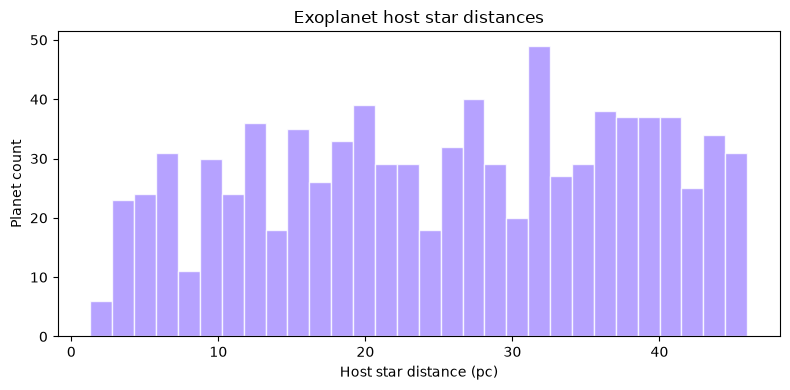

In [5]:
# Exoplanet host stars: metallicity comparison
exo = pd.read_csv(f'{BASE}/data/processed/local_volume_exoplanets.csv')
host_names = exo['hostname'].unique()
print(f'Exoplanet host stars: {len(host_names)}')
print(f'Planets per host (median): {exo.groupby("hostname").size().median():.1f}')

# Cross-match hosts to Gaia by name is not trivial; instead show distance distribution of hosts
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(exo['sy_dist'], bins=30, color='#a48bff', edgecolor='white', alpha=0.8)
ax.set_xlabel('Host star distance (pc)')
ax.set_ylabel('Planet count')
ax.set_title('Exoplanet host star distances')
plt.tight_layout(); plt.show()
